# 03 - Normalisation, tokenisation, vocabulary, padding and embeddings

In [1]:
import sys, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
import pandas as pd, numpy as np, matplotlib.pyplot as plt, json
pd.set_option("display.max_colwidth", 160); pd.set_option("display.width", 200)
%matplotlib inline
import torch
from src import config as C
from src.preprocessing import normalize, tokenize, detokenize
from src.vocabulary import Vocabulary
from src.dataset import EventDataset, collate

## Normalisation + tokenisation
* Unicode NFC, typographic apostrophes/quotes → ASCII (`’` → `'`), whitespace collapsed.
* **Lower-casing**: yes, to avoid splitting the vocabulary (Concert / concert); outputs are re-capitalised for display.
* Punctuation becomes separate tokens; French elisions are split (`l'atelier` → `l'` `atelier`);
  hyphenated words and numbers stay whole (`vide-grenier`, `14h30`, `2,5`).

In [2]:
for s in ["Join l’atelier aujourd’hui, à 14h30 !", "Vide-grenier (entrée : 2,5 €)..."]:
    t = tokenize(s); print(s, "\n  ->", t, "\n  <-", detokenize(t))

Join l’atelier aujourd’hui, à 14h30 ! 
  -> ['join', "l'", 'atelier', "aujourd'hui", ',', 'à', '14h30', '!'] 
  <- Join l'atelier aujourd'hui, à 14h30 !
Vide-grenier (entrée : 2,5 €)... 
  -> ['vide-grenier', '(', 'entrée', ':', '2,5', '€', ')', '...'] 
  <- Vide-grenier (entrée : 2,5 €)...


In [3]:
train = pd.read_csv(C.SPLIT_FILES['train']); test = pd.read_csv(C.SPLIT_FILES['test'])
for i in range(3):
    print('RAW :', train.target_text[i]); print('PREP:', tokenize(train.target_text[i])); print()

RAW : Au profit de l'association RIRE MEDECIN La troupe des Gens du coin présente la pièce d'Olivier Tourancheau "Arrêtez vos salades!". Comédie pétillante en deux actes où mensonges et quiproquos sèment une sacrée pagaille dans le domaine équestre familial. A savourer sans modération !
PREP: ['au', 'profit', 'de', "l'", 'association', 'rire', 'medecin', 'la', 'troupe', 'des', 'gens', 'du', 'coin', 'présente', 'la', 'pièce', "d'", 'olivier', 'tourancheau', '"', 'arrêtez', 'vos', 'salades', '!', '"', '.', 'comédie', 'pétillante', 'en', 'deux', 'actes', 'où', 'mensonges', 'et', 'quiproquos', 'sèment', 'une', 'sacrée', 'pagaille', 'dans', 'le', 'domaine', 'équestre', 'familial', '.', 'a', 'savourer', 'sans', 'modération', '!']

RAW : Visite libre de l'ancienne synagogue de Delme et son patrimoine architectural. Un historique complet du bâtiment est à votre disposition à l'accueil. Ancienne synagogue de style oriental et inaugurée en 1881, elle est conçue sur le modèle de la synagogue de B

## Vocabularies (built on the TRAINING split only)

In [4]:
src_v = Vocabulary.load(C.SRC_VOCAB_FILE); tgt_v = Vocabulary.load(C.TGT_VOCAB_FILE)
print('source vocab', len(src_v), '| target vocab', len(tgt_v))
print(src_v.idx2word[:12]); print(tgt_v.stats()['top_20'])

source vocab 8523 | target vocab 14583
['<pad>', '<unk>', '<sos>', '<eos>', ':', ',', '|', 'titre', 'type', 'événement', 'culturel', 'de']
[('de', 40635), (',', 39601), ('.', 29976), ('et', 23657), ('la', 20437), ('à', 17065), ('le', 14220), ("l'", 13400), ('les', 11961), ('des', 11420), ("d'", 10636), ('du', 10540), ('un', 10237), ('une', 9328), ('pour', 7603), ('en', 7539), ('!', 7396), ('au', 6413), ('"', 6367), ('dans', 5437)]


In [5]:
for name, df in [('train', train), ('test', test)]:
    print(name, 'target coverage (share of tokens known):', round(tgt_v.coverage(tokenize(t) for t in df.target_text), 4))

train target coverage (share of tokens known): 0.9554
test target coverage (share of tokens known): 0.9406


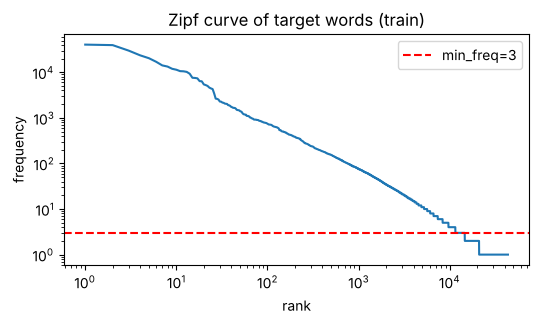

In [6]:
freqs = pd.Series(tgt_v.freqs).sort_values(ascending=False).values
plt.figure(figsize=(6,3)); plt.loglog(range(1, len(freqs)+1), freqs)
plt.axhline(tgt_v.min_freq, color='r', ls='--', label=f'min_freq={tgt_v.min_freq}')
plt.title('Zipf curve of target words (train)'); plt.xlabel('rank'); plt.ylabel('frequency'); plt.legend(); plt.show()

Special tokens: `<pad>`=0 fills batches (ignored by the loss, masked in attention), `<unk>`=1 replaces
words below `min_freq` or unseen, `<sos>`=2 starts decoding, `<eos>`=3 ends it.

## Numerical encoding, padding and masks

In [7]:
ds = EventDataset(train.head(4), src_v, tgt_v, 40, 60)
print(train.input_text[0]); print(ds.src[0])
print([src_v.idx2word[i] for i in ds.src[0]])
src, src_len, tgt, _ = collate([ds[i] for i in range(4)])
print('src', tuple(src.shape), 'lengths', src_len.tolist()); print(src)
print('mask (True = real token)'); print(src != 0)

type : spectacle , événement culturel | titre : 'Arrêtez vos salades!'
[8, 4, 14, 5, 9, 10, 6, 7, 4, 48, 1, 527, 1, 50, 48]
['type', ':', 'spectacle', ',', 'événement', 'culturel', '|', 'titre', ':', "'", '<unk>', 'vos', '<unk>', '!', "'"]
src (4, 24) lengths [15, 18, 24, 10]
tensor([[   8,    4,   14,    5,    9,   10,    6,    7,    4,   48,    1,  527,
            1,   50,   48,    0,    0,    0,    0,    0,    0,    0,    0,    0],
        [   8,    4,   16,   17,    6,    7,    4,   34,  348,   11,   27, 1797,
         8168,   11,    1,    5,  111,  550,    0,    0,    0,    0,    0,    0],
        [   8,    4,   40,   41,    5,   56,    5,   51,    5,    9,   10,    6,
            7,    4,   85,    5,  290,   11,   65,   12,  997,  115,  556,   50],
        [   8,    4,   16,   17,    6,    7,    4,    1,   48, 5611,    0,    0,
            0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0]])
mask (True = real token)
tensor([[ True,  True,  True,  True,  True,  

## Embeddings
A token id is an arbitrary integer: id 812 is not "closer" to 813 than to 5. `nn.Embedding(V, 128)` is a
learnable V×128 matrix whose row *i* is the dense vector of word *i*; it is updated by backpropagation like
any weight, so words used in similar contexts end up with similar vectors. `padding_idx=0` keeps the
`<pad>` vector at zero.

In [8]:
emb = torch.nn.Embedding(len(src_v), 128, padding_idx=0)
x = emb(src)
print('ids', tuple(src.shape), '-> vectors', tuple(x.shape)); print('pad vector norm:', emb.weight[0].norm().item())

ids (4, 24) -> vectors (4, 24, 128)
pad vector norm: 0.0


In [9]:
from src.training import load_model
import torch.nn.functional as F
if (C.MODELS_DIR / 'attention' / 'best.pt').exists():
    m, _ = load_model(C.MODELS_DIR / 'attention', 'cpu'); E = m.decoder.embedding.weight.detach()
    for w in ['concert', 'marché', 'enfants', 'randonnée']:
        if w in tgt_v.word2idx:
            sims = F.cosine_similarity(E[tgt_v.word2idx[w]].unsqueeze(0), E)
            print(w, '->', [tgt_v.idx2word[i] for i in sims.topk(7).indices.tolist()[1:]])